In [ ]:
#importamos las ibrerias necesarias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import linregress

In [ ]:
# 1. Cargar los datasets
stats_url = "https://drive.google.com/uc?id=1LxkcMGkaHML90Byj7629y-byZz5FGoU-"
stats_df = pd.read_csv(stats_url)

results_url = "https://drive.google.com/uc?id=1E36QY6b0PSxwjzQpglaHcHC0Jbl2dqs4"
results_df = pd.read_csv(results_url)

# Limpiar nulos básicos
results_df.dropna(subset=['home_team', 'away_team', 'season', 'result'], inplace=True)
stats_df.dropna(subset=['team', 'season'], inplace=True)

# 2. INGENIERÍA DE CARACTERÍSTICAS: Calcular rachas sin ordenar por fecha
def calcular_racha(df, equipo_col, feature_col, n_partidos=5):
    # El .shift(1) oculta el partido actual para evitar fuga de datos
    return df.groupby(equipo_col)[feature_col].transform(lambda x: x.shift(1).rolling(n_partidos).mean())

results_df['home_form_goals'] = calcular_racha(results_df, 'home_team', 'home_goals', 5)
results_df['away_form_goals'] = calcular_racha(results_df, 'away_team', 'away_goals', 5)

# Llenar los nulos generados en los primeros partidos
results_df['home_form_goals'] = results_df['home_form_goals'].fillna(0)
results_df['away_form_goals'] = results_df['away_form_goals'].fillna(0)

# 3. ELIMINAR FUGA DE DATOS: Ajustar el formato de texto "2006-2007"
def obtener_temporada_anterior(temporada):
    if pd.isna(temporada):
        return temporada
    anio_inicio, anio_fin = str(temporada).split('-')
    return f"{int(anio_inicio) - 1}-{int(anio_fin) - 1}"

# Aplicamos la función para crear 'prev_season'
results_df['prev_season'] = results_df['season'].apply(obtener_temporada_anterior)

# 4. FUSIONAR (Merge) cruzando con la temporada anterior
merged_df = results_df.merge(
    stats_df,
    left_on=['home_team', 'prev_season'],
    right_on=['team', 'season'],
    how='inner'
)

merged_df = merged_df.merge(
    stats_df,
    left_on=['away_team', 'prev_season'],
    right_on=['team', 'season'],
    how='inner',
    suffixes=('_home', '_away')
)

print(f"Dataset listo: Rachas calculadas y Fuga de Datos eliminada.")
print(f"Total de partidos viables: {merged_df.shape[0]}")

Dataset listo: Rachas calculadas y Fuga de Datos eliminada.
Total de partidos viables: 2992


In [ ]:
# Creación de variables de diferencia (Feature Engineering)
# Ejemplo: Diferencia de victorias acumuladas, goles o tiros al arco.

try:
    merged_df['diff_wins'] = merged_df['wins_home'] - merged_df['wins_away']
    merged_df['diff_goals'] = merged_df['goals_home'] - merged_df['goals_away']
    merged_df['diff_tiros_puerta'] = merged_df['ontarget_scoring_att_home'] - merged_df['ontarget_scoring_att_away']
    print("Variables de diferencia creadas correctamente.")
except KeyError:
    print("Revisa los nombres exactos de tus columnas para crear las diferencias.")

Variables de diferencia creadas correctamente.


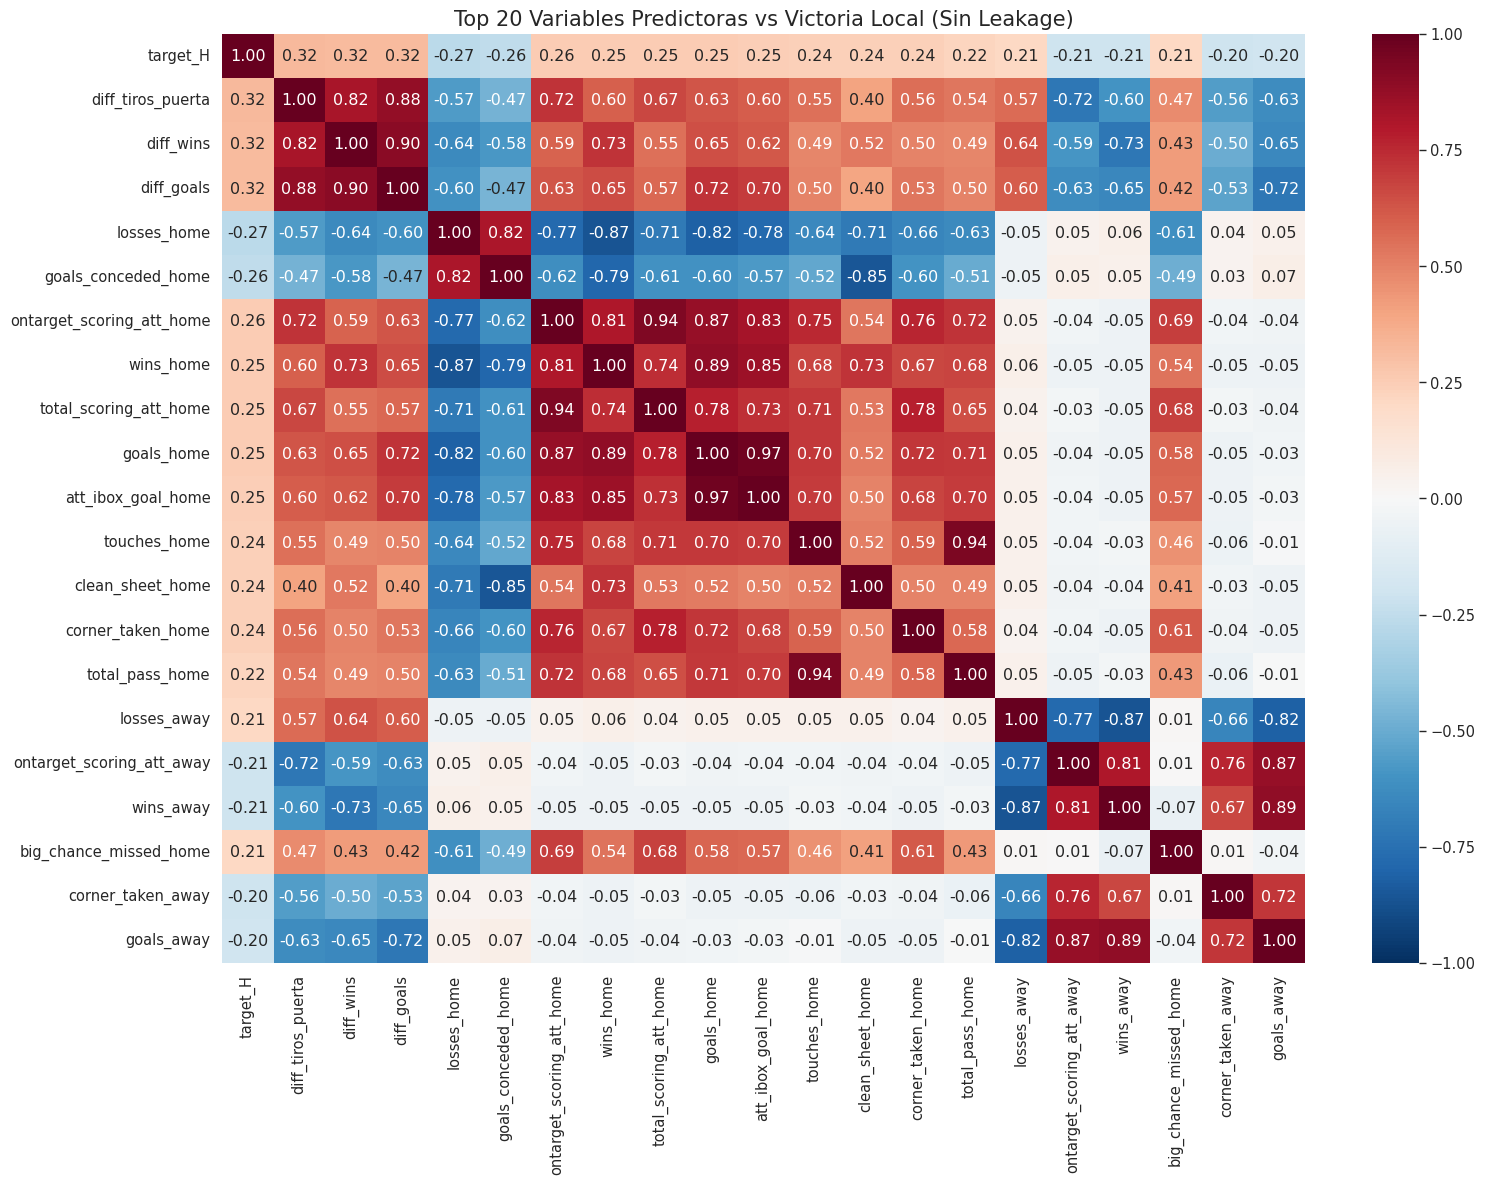

In [ ]:
# 1. Nos quedamos solo con variables numéricas y eliminamos los goles del partido actual si existen
cols_numericas = merged_df.select_dtypes(include=[np.number]).columns
cols_a_eliminar = ['home_goals', 'away_goals']
cols_predictoras = [col for col in cols_numericas if col not in cols_a_eliminar]

numeric_df = merged_df[cols_predictoras].copy()

# 2. Creamos el target binario SOLO para medir la correlación lineal
numeric_df['target_H'] = (merged_df['result'] == 'H').astype(int)

# 3. Calculamos la correlación con la victoria local y tomamos el Top 20 absoluto
correlations = numeric_df.corr()['target_H'].abs().sort_values(ascending=False)
top_features = list(correlations.index[1:21]) # El índice 0 es 'target_H', lo saltamos

# 4. Generamos el Heatmap del Top 20
selected_cols = ['target_H'] + top_features
corr_matrix = numeric_df[selected_cols].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', fmt=".2f", vmin=-1, vmax=1)
plt.title('Top 20 Variables Predictoras vs Victoria Local (Sin Leakage)', fontsize=15)
plt.tight_layout()
plt.show()




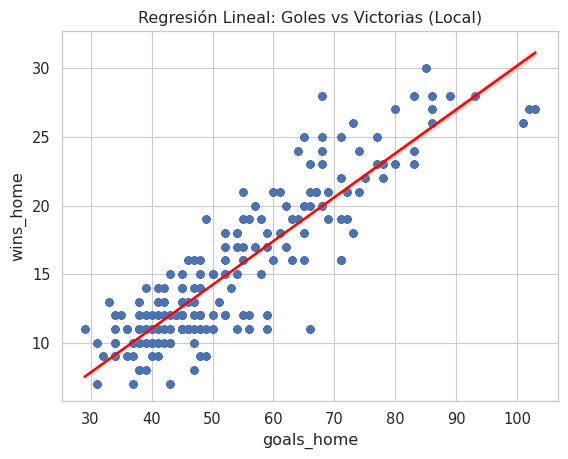

Ecuación de la recta: y = 0.319x + -1.741
Coeficiente de determinación (R^2): 0.789


In [ ]:
#Aqui hacemos un scatteplot q sirve para ver la relación que hay entre variables, en esta grafica usamos los goles en casa y las victorias en casa y vemos q hay una relación bastante directa
#escogimos esta para ver q tan relacionadas estaban pero se puede usar con cualquier otra variable y sirve para analizar q tan relacionadas estan al igual q el heatmap
sns.regplot(data=numeric_df, x="goals_home", y="wins_home",
            line_kws={"color": "red"}, scatter_kws={"alpha": 0.5})

plt.title("Regresión Lineal: Goles vs Victorias (Local)")
plt.show()

# Calcular la regresión lineal
reg = linregress(numeric_df["goals_home"], numeric_df["wins_home"])

# Mostrar los resultados
print(f"Ecuación de la recta: y = {reg.slope:.3f}x + {reg.intercept:.3f}")
print(f"Coeficiente de determinación (R^2): {reg.rvalue**2:.3f}")

/tmp/ipykernel_1802/2396992339.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=merged_df, x='result', palette='viridis', order=['H', 'A', 'D'])


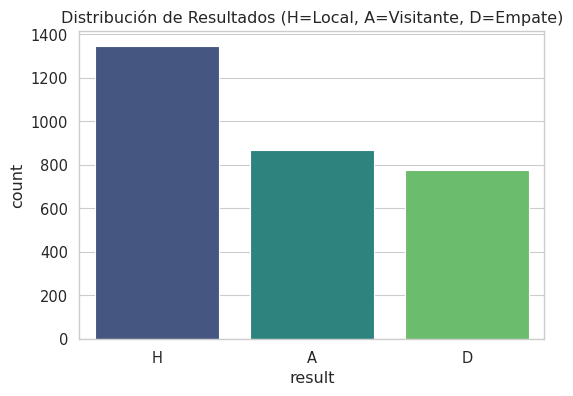

--- Estadísticas Categórica ---
        Conteo  Porcentaje (%)
result                        
H         1348           45.05
A          868           29.01
D          776           25.94


In [ ]:
# ==========================================
# REQUISITO 1: Variable Categórica (Resultado del partido - result)
# ==========================================
plt.figure(figsize=(6,4))
sns.countplot(data=merged_df, x='result', palette='viridis', order=['H', 'A', 'D'])
plt.title('Distribución de Resultados (H=Local, A=Visitante, D=Empate)')
plt.show()

# Estadísticas: Frecuencia y Porcentaje
frec = merged_df['result'].value_counts()
porc = merged_df['result'].value_counts(normalize=True) * 100
print("--- Estadísticas Categórica ---")
print(pd.DataFrame({'Conteo': frec, 'Porcentaje (%)': porc.round(2)}))

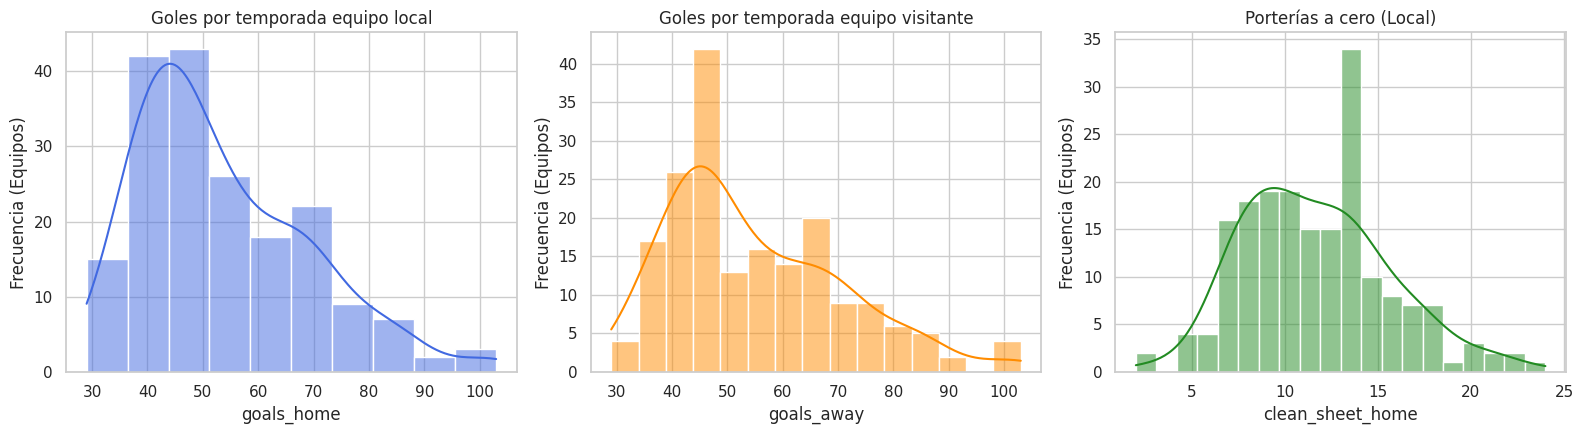

In [ ]:

# 1. Filtramos para quedarnos con un solo registro por equipo y temporada
df_stats_unicos = merged_df.drop_duplicates(subset=['season', 'home_team']).copy()

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 2. Graficamos usando el nuevo dataframe sin duplicados
sns.histplot(df_stats_unicos['goals_home'], bins=10, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Goles por temporada equipo local')
axes[0].set_ylabel('Frecuencia (Equipos)')

sns.histplot(df_stats_unicos['goals_away'], bins=15, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Goles por temporada equipo visitante')
axes[1].set_ylabel('Frecuencia (Equipos)')

sns.histplot(df_stats_unicos['clean_sheet_home'], bins=20, kde=True, ax=axes[2], color='forestgreen')
axes[2].set_title('Porterías a cero (Local)')
axes[2].set_ylabel('Frecuencia (Equipos)')

plt.tight_layout()
plt.show()

--- Estadísticas Numérica Simétrica: clean_sheet_home ---
Media: 11.66 ± 3.96 (desv. estándar)


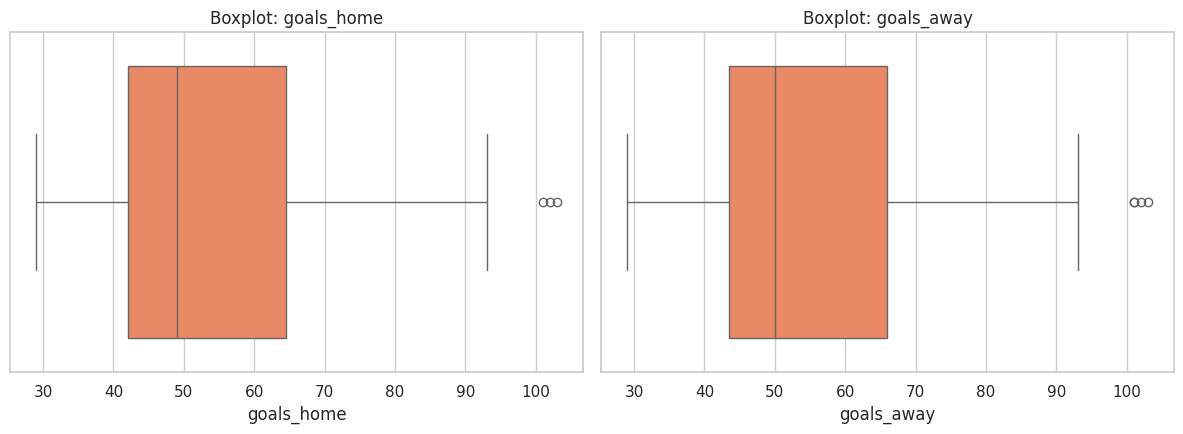

--- Estadísticas Numéricas Asimétricas ---
goals_home: mediana=49.0, IQR=42.0-64.5, rango=29.0-103.0
goals_away: mediana=50.0, IQR=43.5-66.0, rango=29.0-103.0


In [ ]:
# ==========================================
# REQUISITO 2: Variable Numérica Simétrica (clean_sheet_home)
# ==========================================
media_cs = df_stats_unicos['clean_sheet_home'].mean()
std_cs = df_stats_unicos['clean_sheet_home'].std()

print("--- Estadísticas Numérica Simétrica: clean_sheet_home ---")
print(f"Media: {media_cs:.2f} ± {std_cs:.2f} (desv. estándar)")

# ==========================================
# REQUISITO 3: Variables Numéricas Asimétricas (goals_home, goals_away)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, col in zip(axes, ['goals_home', 'goals_away']):
    sns.boxplot(x=df_stats_unicos[col], ax=ax, color='coral')
    ax.set_title(f'Boxplot: {col}')

plt.tight_layout()
plt.show()

print("--- Estadísticas Numéricas Asimétricas ---")
for col in ['goals_home', 'goals_away']:
    mediana = df_stats_unicos[col].median()
    q1 = df_stats_unicos[col].quantile(0.25)
    q3 = df_stats_unicos[col].quantile(0.75)
    print(f"{col}: mediana={mediana:.1f}, IQR={q1:.1f}-{q3:.1f}, rango={df_stats_unicos[col].min()}-{df_stats_unicos[col].max()}")


In [ ]:
columnas_numericas = merged_df.select_dtypes(include=['float64', 'int64']).columns

# Rellenamos los nulos con el promedio de cada equipo específico para no distorsionar el rendimiento
if 'home_team' in merged_df.columns:
    merged_df[columnas_numericas] = merged_df.groupby('home_team')[columnas_numericas].transform(lambda x: x.fillna(x.mean()))
else:
    # Respaldo en caso de que no esté el nombre del equipo
    merged_df[columnas_numericas] = merged_df[columnas_numericas].fillna(merged_df[columnas_numericas].mean())

print("Valores nulos tras la imputación:", merged_df[columnas_numericas].isnull().sum().sum())




Valores nulos tras la imputación: 544


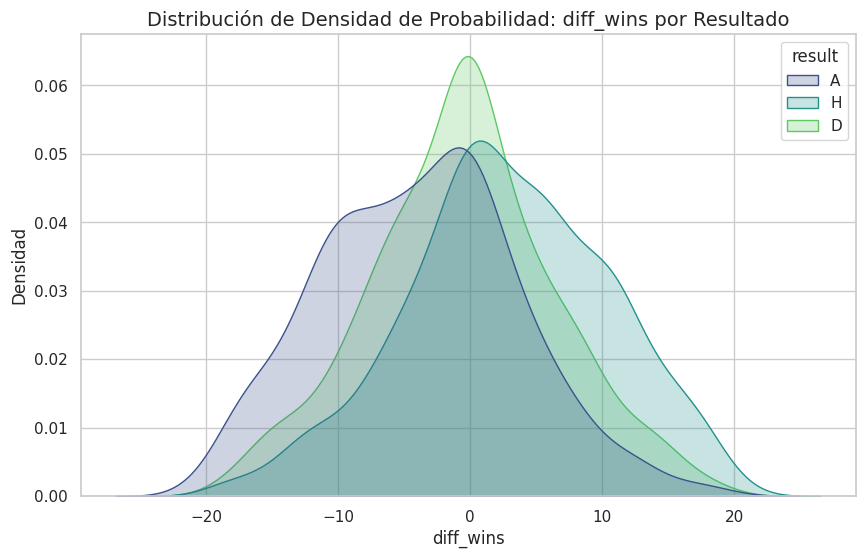

In [ ]:
# NUEVA CELDA AL FINAL: Codificación Multiclase y Gráfica de Densidad

# 1. Codificar el resultado final para entrenar modelos de Machine Learning (0, 1, 2)
mapeo_resultados = {'A': 0, 'D': 1, 'H': 2}
merged_df['target_multiclase'] = merged_df['result'].map(mapeo_resultados)

# 2. Visualizar la densidad de probabilidad de una variable clave según el resultado
# Reemplaza 'diff_wins' por la variable que haya tenido mejor correlación en tu heatmap
variable_clave = 'diff_wins'

if variable_clave in merged_df.columns:
    plt.figure(figsize=(10, 6))
    sns.kdeplot(data=merged_df, x=variable_clave, hue='result', common_norm=False, fill=True, palette='viridis')
    plt.title(f'Distribución de Densidad de Probabilidad: {variable_clave} por Resultado', fontsize=14)
    plt.xlabel(variable_clave)
    plt.ylabel('Densidad')
    plt.show()

In [ ]:
merged_df.head()

,home_team,away_team,home_goals,away_goals,result,season_x,home_form_goals,away_form_goals,prev_season,team_home,...,clearance_off_line_away,dispossessed_away,penalty_save_away,total_high_claim_away,punches_away,season,diff_wins,diff_goals,diff_tiros_puerta,target_multiclase
0,Bolton Wanderers,Newcastle United,1.0,3.0,A,2007-2008,1.2,0.8,2006-2007,Bolton Wanderers,...,9.0,538.421875,0.0,48.0,26.0,2006-2007,5.0,9.0,-20.0,0
1,Everton,Wigan Athletic,2.0,1.0,H,2007-2008,2.4,0.8,2006-2007,Everton,...,4.0,480.506250,2.0,61.0,29.0,2006-2007,5.0,15.0,6.0,2
2,Middlesbrough,Blackburn Rovers,1.0,2.0,A,2007-2008,2.0,1.4,2006-2007,Middlesbrough,...,8.0,613.875000,5.0,56.0,25.0,2006-2007,-3.0,-8.0,-11.0,0
3,West Ham United,Manchester City,0.0,2.0,A,2007-2008,2.0,1.4,2006-2007,West Ham United,...,4.0,484.218750,1.0,64.0,17.0,2006-2007,1.0,6.0,-13.0,0
4,Aston Villa,Liverpool,1.0,2.0,A,2007-2008,1.0,0.6,2006-2007,Aston Villa,...,1.0,495.007812,0.0,51.0,27.0,2006-2007,-9.0,-14.0,-60.0,0


# SEGUNDA ENTREGA DEL PROYECTO

En esta segunda entrega del proyecto, vamos a aplicar los 4 modelos de clasificación visto en clase que son GNB, decision tree, random forest y SVM. Primero corregimos errores de la entrega pasada.


/tmp/ipykernel_1802/3868383845.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_entrega2, x='clase_objetivo', palette='viridis', edgecolor='black')


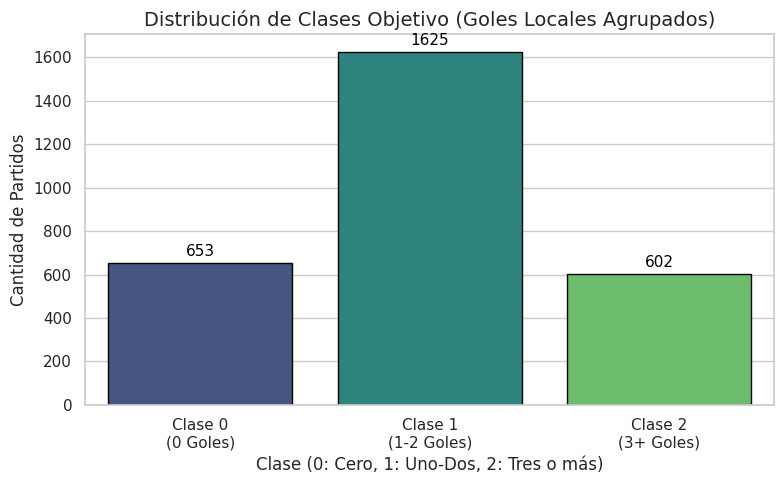

Proporción de las nuevas clases:
Clase 1: 56.42%
Clase 0: 22.67%
Clase 2: 20.9%


In [ ]:
# 0. Crear la copia independiente para no afectar la entrega 1
df_entrega2 = merged_df.copy()
df_entrega2 = df_entrega2.dropna()
# 1. Función para agrupar los goles en las 3 clases definidas
def categorizar_goles(goles):
    if goles == 0:
        return 0  # Clase 0: 0 goles
    elif goles in [1, 2]:
        return 1  # Clase 1: 1 a 2 goles
    else:
        return 2  # Clase 2: 3 goles o más

# Crear la nueva columna objetivo aplicando la función en la COPIA
df_entrega2['clase_objetivo'] = df_entrega2['home_goals'].apply(categorizar_goles)

# 2. Generar la gráfica de la nueva distribución de clases
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_entrega2, x='clase_objetivo', palette='viridis', edgecolor='black')

# Configurar etiquetas y títulos
plt.title('Distribución de Clases Objetivo (Goles Locales Agrupados)', fontsize=14)
plt.xlabel('Clase (0: Cero, 1: Uno-Dos, 2: Tres o más)', fontsize=12)
plt.ylabel('Cantidad de Partidos', fontsize=12)

# Añadir las etiquetas de texto sobre cada barra
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline',
                fontsize=11, color='black',
                xytext=(0, 5), textcoords='offset points')

# Personalizar el eje X para mayor claridad
plt.xticks(ticks=[0, 1, 2], labels=['Clase 0\n(0 Goles)', 'Clase 1\n(1-2 Goles)', 'Clase 2\n(3+ Goles)'])

plt.tight_layout()
plt.show()

# 3. Validar las proporciones de las nuevas clases
print("Proporción de las nuevas clases:")
proporciones = (df_entrega2['clase_objetivo'].value_counts(normalize=True) * 100).round(2)
for clase, prop in proporciones.items():
    print(f"Clase {clase}: {prop}%")

In [ ]:
#Creamos la nueva variable objetivo multiclase en este nuevo DataFrame
df_entrega2['clase_objetivo'] = df_entrega2['home_goals'].apply(categorizar_goles)

# Tomamos la lista de las 20 mejores variables (top_features) que ya habías calculado
# Y LE SUMAMOS explícitamente la 'clase_objetivo' para que no se elimine en el siguiente paso
columnas_definitivas = top_features + ['clase_objetivo']

#Filtramos el DataFrame de la segunda entrega usando esa lista combinada
df_entrega2 = df_entrega2[columnas_definitivas]

# Verificamos que todo esté en orden (deberías tener 21 columnas)
print(f"Dataset de la Segunda Entrega listo para entrenar. Dimensión: {df_entrega2.shape}")

Dataset de la Segunda Entrega listo para entrenar. Dimensión: (2880, 21)


In [ ]:
df_entrega2.shape

(2880, 21)

In [ ]:
#corregir las variables que vamos a utilizar debido a que estan muy relacionadas entre si causando un problema de multicolinealidad

# Subimos el umbral a 0.85 para filtrar solo las que sean casi idénticas
umbral = 0.85

# Calcular la matriz de correlación
corr_matrix = df_entrega2.corr(numeric_only=True).abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

print(f"Parejas de variables con correlación mayor a {umbral}:\n")

# Extraer y mostrar las parejas conflictivas
parejas = []
for col in upper_tri.columns:
    for idx in upper_tri.index:
        valor_corr = upper_tri.loc[idx, col]
        if pd.notna(valor_corr) and valor_corr > umbral:
            parejas.append((idx, col, valor_corr))

# Ordenar de mayor a menor correlación
parejas.sort(key=lambda x: x[2], reverse=True)

for var1, var2, corr in parejas:
    print(f" '{var1}' choca con '{var2}' (Correlación: {corr:.2f})")

Parejas de variables con correlación mayor a 0.85:

 'goals_home' choca con 'att_ibox_goal_home' (Correlación: 0.98)
 'touches_home' choca con 'total_pass_home' (Correlación: 0.95)
 'ontarget_scoring_att_home' choca con 'total_scoring_att_home' (Correlación: 0.94)
 'diff_wins' choca con 'diff_goals' (Correlación: 0.90)
 'wins_away' choca con 'goals_away' (Correlación: 0.89)
 'wins_home' choca con 'goals_home' (Correlación: 0.89)
 'diff_tiros_puerta' choca con 'diff_goals' (Correlación: 0.88)
 'ontarget_scoring_att_home' choca con 'goals_home' (Correlación: 0.87)
 'ontarget_scoring_att_away' choca con 'goals_away' (Correlación: 0.87)
 'losses_home' choca con 'wins_home' (Correlación: 0.87)
 'losses_away' choca con 'wins_away' (Correlación: 0.87)
 'wins_home' choca con 'att_ibox_goal_home' (Correlación: 0.86)
 'goals_conceded_home' choca con 'clean_sheet_home' (Correlación: 0.85)


In [ ]:
# Lista de columnas seleccionadas manualmente (incluyendo las repetidas)
columnas_a_eliminar = [
    'att_ibox_goal_home', 'att_ibox_goal_away',
    'touches_away', 'touches_home',
    'ontarget_scoring_att_home', 'ontarget_scoring_att_away',
    'head_clearance_away', 'saves_away',
    'head_clearance_home', 'losses_home', 'losses_away',
    'ontarget_scoring_att_away', 'ontarget_scoring_att_home', # Duplicados
    'goals_conceded_home', 'goals_conceded_away'
]

# Eliminar duplicados de la lista y borrar las columnas del DataFrame
columnas_unicas = list(set(columnas_a_eliminar))

# errors='ignore' evita que el código falle si alguna columna ya había sido eliminada
df_entrega2 = df_entrega2.drop(columns=columnas_unicas, errors='ignore')

print(f"Se eliminaron {len(columnas_unicas)} columnas redundantes.")
print(f"Tu dataset ahora tiene {df_entrega2.shape[1]} variables en total.")

Se eliminaron 13 columnas redundantes.
Tu dataset ahora tiene 14 variables en total.


In [ ]:
df_entrega2.head()

,diff_tiros_puerta,diff_wins,diff_goals,wins_home,total_scoring_att_home,goals_home,clean_sheet_home,corner_taken_home,total_pass_home,wins_away,big_chance_missed_home,corner_taken_away,goals_away,clase_objetivo
0,-20.0,5.0,9.0,16.0,404.0,47.0,12.0,217.0,12400.0,11.0,42.000000,195.0,38.0,1
1,6.0,5.0,15.0,15.0,465.0,52.0,14.0,208.0,12274.0,10.0,42.000000,177.0,37.0,1
3,-13.0,1.0,6.0,12.0,461.0,35.0,9.0,196.0,13178.0,11.0,34.200000,198.0,29.0,0
4,-60.0,-9.0,-14.0,11.0,470.0,43.0,13.0,213.0,13254.0,20.0,36.400000,282.0,57.0,1
5,84.0,11.0,25.0,19.0,638.0,63.0,12.0,278.0,18458.0,8.0,60.428571,173.0,38.0,1


In [ ]:
df_entrega2.shape

(2880, 14)

In [ ]:
#importamos todas las nuevas funciones de la libreria sklearn q necesitamos
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             make_scorer)
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold


In [ ]:
def metric_row(name, y_true, y_pred):
    return {'Modelo': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, zero_division=0),
            'Recall': recall_score(y_true, y_pred, zero_division=0),
            'F1': f1_score(y_true, y_pred, zero_division=0)}

SEED=18


# X son todas las columnas excepto la clase objetivo
X = df_entrega2.drop(columns=['clase_objetivo'])

# y_binaria se calcula directamente de la columna 'clase_objetivo' (0: no anota, 1: anota)
y_binaria = (df_entrega2['clase_objetivo'] > 0).astype(int).copy()

# 2. Partición con la nueva variable binaria
X_dev, X_test, y_dev, y_test = train_test_split(X, y_binaria, test_size=0.20, stratify=y_binaria, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

# 3. Inicializar los 4 modelos base
candidates = {'GNB': GaussianNB(),
              'DT': DecisionTreeClassifier(max_depth=2, class_weight='balanced', random_state=SEED),
              'RF': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=SEED, n_jobs=-1),
              'SVM': make_pipeline(StandardScaler(), SVC(C=1, class_weight='balanced', gamma='scale'))
              }
rows=[]

for name, estimator in candidates.items():
    model = clone(estimator)
    model.fit(X_train, y_train)
    rows.append(metric_row(name, y_val, model.predict(X_val)))

validation_results = pd.DataFrame(rows).set_index('Modelo')
display(validation_results.round(3))

selected_name = validation_results['F1'].idxmax()
print(f'Modelo seleccionado por F1 de validación: {selected_name}')




,Accuracy,Precision,Recall,F1
Modelo,,,,
GNB,0.649,0.827,0.690,0.752
DT,0.488,0.841,0.416,0.556
RF,0.740,0.773,0.939,0.848
SVM,0.620,0.840,0.627,0.718


Modelo seleccionado por F1 de validación: RF


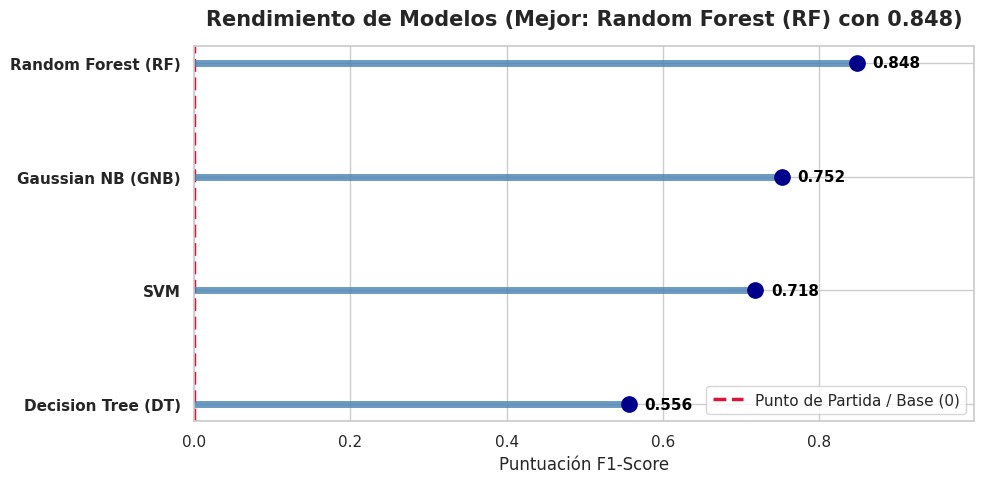

In [ ]:
# 1. Datos actualizados con tu tabla
datos_modelos = {
    'Modelo': ['Decision Tree (DT)', 'SVM', 'Gaussian NB (GNB)', 'Random Forest (RF)'],
    'F1_Score': [0.556, 0.718, 0.752, 0.848]
}
df_resultados = pd.DataFrame(datos_modelos)
df_resultados = df_resultados.sort_values(by='F1_Score').reset_index(drop=True)

mejor_f1 = df_resultados['F1_Score'].max()
mejor_modelo = df_resultados.loc[df_resultados['F1_Score'].idxmax(), 'Modelo']

# 2. Configuración visual
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")
y_pos = np.arange(len(df_resultados))

# 3. LÍNEA ROJA PUNTEADA A LA IZQUIERDA (en x=0) como punto de partida
plt.axvline(x=0, color='crimson', linestyle='--', linewidth=2.5,
            label=f'Punto de Partida / Base (0)')

# 4. LAS LÍNEAS NACEN EN 0 Y LLEGAN HASTA SU VALOR CORRESPONDIENTE
plt.hlines(y=y_pos, xmin=0, xmax=df_resultados['F1_Score'],
           color='steelblue', alpha=0.8, linewidth=5)

# 5. Dibujar los puntos exactos donde terminan
plt.plot(df_resultados['F1_Score'], y_pos, "o", markersize=11, color='darkblue')

# 6. Textos con los números al final de cada línea
for i, valor in enumerate(df_resultados['F1_Score']):
    plt.text(valor + 0.02, i, f'{valor:.3f}', va='center', ha='left',
             color='black', fontweight='bold', fontsize=11)

# 7. Diseño final
plt.yticks(y_pos, df_resultados['Modelo'], fontsize=11, fontweight='bold')
plt.xlabel('Puntuación F1-Score', fontsize=12)
plt.title(f'Rendimiento de Modelos (Mejor: {mejor_modelo} con {mejor_f1})', fontsize=15, fontweight='bold', pad=15)

# Forzamos a que la gráfica empiece en 0 a la izquierda y le damos espacio a la derecha
plt.xlim(0, mejor_f1 + 0.15)

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
# 1. Ajustamos la función de métricas para que soporte Multiclase (usando average='macro')
def metric_row_multi(name, y_true, y_pred):
    return {'Modelo': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision (Macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'Recall (Macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
            'F1 (Macro)': f1_score(y_true, y_pred, average='macro', zero_division=0)}

SEED = 18

# Definimos X e y sincronizados desde el dataset limpio
X = df_entrega2.drop(columns=['clase_objetivo'])
y = df_entrega2['clase_objetivo'].copy()

# 2. Realizamos la partición estratificada respetando las 3 clases
X_dev_m, X_test_m, y_dev_m, y_test_m = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train_m, X_val_m, y_train_m, y_val_m = train_test_split(X_dev_m, y_dev_m, test_size=0.25, stratify=y_dev_m, random_state=SEED)

# 3. Define aquí TUS DOS MEJORES MODELOS según el DataFrame binario anterior
top_candidates = {
    'GNB': GaussianNB(),
    'RF': RandomForestClassifier(n_estimators=100, max_depth=3, class_weight='balanced', random_state=SEED, n_jobs=-1),
}

rows_multi = []
print("Clases únicas que el modelo va a predecir:", np.unique(y_train_m))
print("Cantidad de partidos por clase en el entrenamiento:\n", y_train_m.value_counts())
for name, estimator in top_candidates.items():
    model = clone(estimator)
    model.fit(X_train_m, y_train_m)
    y_pred_m = model.predict(X_val_m)
    rows_multi.append(metric_row_multi(name, y_val_m, y_pred_m))

# 4. Mostrar resultados multiclase
multi_results = pd.DataFrame(rows_multi).set_index('Modelo')
print("Resultados de Validación - Formato MULTICLASE (0, 1, 2):")
display(multi_results.round(3))

Clases únicas que el modelo va a predecir: [0 1 2]
Cantidad de partidos por clase en el entrenamiento:
 clase_objetivo
1    975
0    391
2    362
Name: count, dtype: int64
Resultados de Validación - Formato MULTICLASE (0, 1, 2):


,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
Modelo,,,,
GNB,0.493,0.476,0.513,0.482
RF,0.457,0.469,0.515,0.456


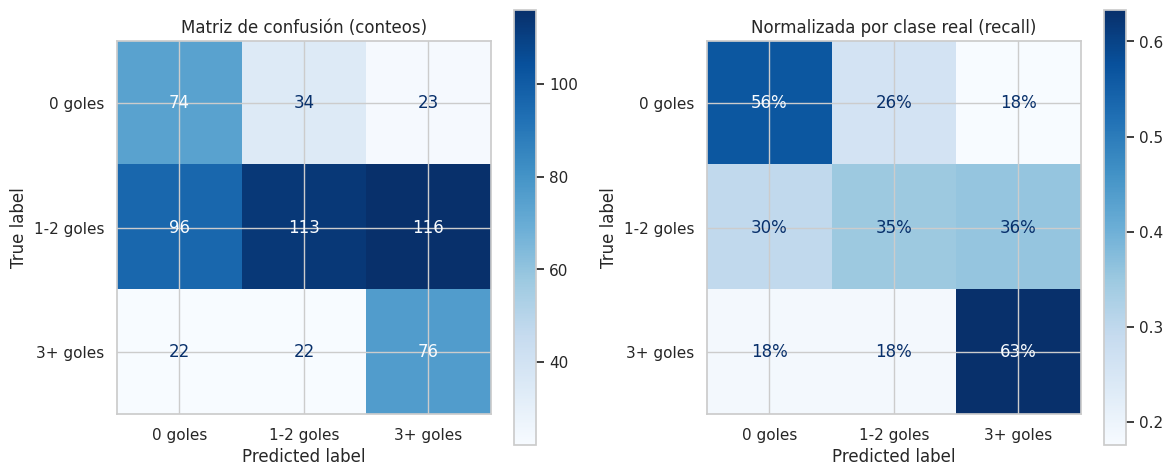

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_val_m, y_pred_m, ax=axes[0], cmap='Blues',
    display_labels=['0 goles', '1-2 goles', '3+ goles'])
axes[0].set_title('Matriz de confusión (conteos)')

ConfusionMatrixDisplay.from_predictions(
    y_val_m, y_pred_m, ax=axes[1], cmap='Blues', normalize='true',
    values_format='.0%',
    display_labels=['0 goles', '1-2 goles', '3+ goles'])
axes[1].set_title('Normalizada por clase real (recall)')
plt.tight_layout(); plt.show()

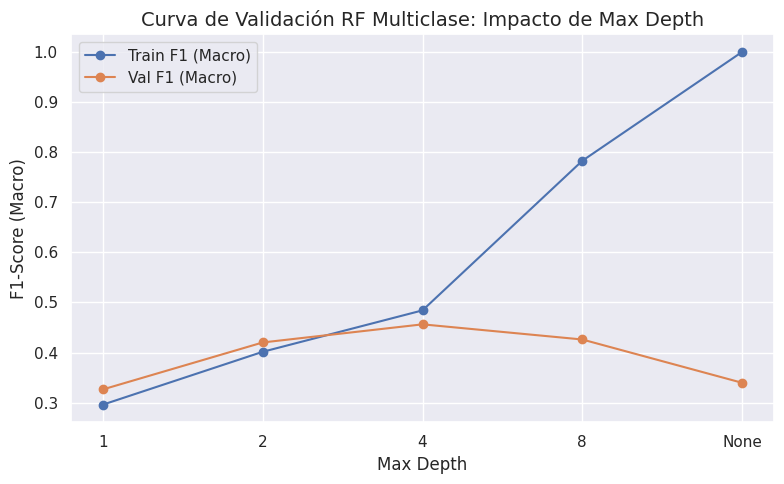

In [ ]:
# 1. Definir las profundidades que queremos evaluar (igual que en tu imagen)
profundidades = [1, 2, 4, 8, None]

train_scores = []
val_scores = []

# 2. Entrenar un Random Forest para cada profundidad y guardar sus métricas
for d in profundidades:
    # Instanciamos el modelo asegurando el class_weight='balanced'
    rf = RandomForestClassifier(max_depth=d, n_estimators=100,
                                class_weight='balanced', random_state=SEED, n_jobs=-1)

    # Entrenamos con el set multiclase
    rf.fit(X_train_m, y_train_m)

    # Predecimos en Train y en Validation
    y_pred_train = rf.predict(X_train_m)
    y_pred_val = rf.predict(X_val_m)

    # Calculamos el F1 Macro para ambos
    train_scores.append(f1_score(y_train_m, y_pred_train, average='macro', zero_division=0))
    val_scores.append(f1_score(y_val_m, y_pred_val, average='macro', zero_division=0))

# 3. Configurar el estilo visual para que quede idéntica a tu referencia
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 5))

# Convertimos las profundidades a texto para que 'None' se vea bien en el eje X
x_labels = [str(d) for d in profundidades]

# Crear las dos líneas de la gráfica
plt.plot(x_labels, train_scores, marker='o', label='Train F1 (Macro)')
plt.plot(x_labels, val_scores, marker='o', label='Val F1 (Macro)')

# Títulos y etiquetas
plt.title('Curva de Validación RF Multiclase: Impacto de Max Depth', fontsize=14)
plt.xlabel('Max Depth', fontsize=12)
plt.ylabel('F1-Score (Macro)', fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()

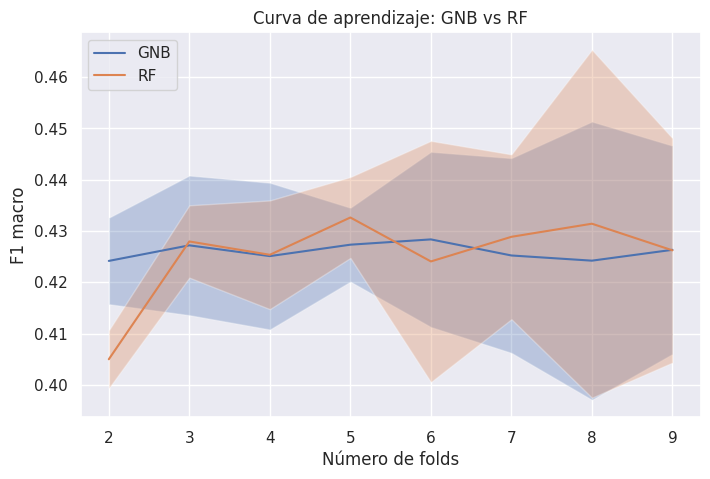

In [ ]:
modelos = {
    'GNB': GaussianNB(),
    'RF': RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=SEED, n_jobs=-1),
}

plt.figure(figsize=(8, 5))
folds = range(2, 10)

for nombre, modelo in modelos.items():
    medias, stds = [], []
    for k in folds:
        s = cross_val_score(modelo, X_dev_m, y_dev_m,
                            cv=StratifiedKFold(k, shuffle=True, random_state=SEED),
                            scoring='f1_macro')
        medias.append(s.mean())
        stds.append(s.std())
    medias, stds = np.array(medias), np.array(stds)
    plt.plot(folds, medias, label=nombre)
    plt.fill_between(folds, medias - stds, medias + stds, alpha=0.3)

plt.xlabel('Número de folds')
plt.ylabel('F1 macro')
plt.title('Curva de aprendizaje: GNB vs RF')
plt.legend()
plt.show()


## ÚLTIMA ENTREGA PROYECTO
En esta entrega aplicaremos 4 modelos de regresiones sobre nuestra variable objetivo, la cuál es predecir la cantidad de goles por el equipo local

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, KFold

In [ ]:
df_entrega3=df_entrega2.copy()

In [ ]:
df_entrega3.head()

,diff_tiros_puerta,diff_wins,diff_goals,wins_home,total_scoring_att_home,goals_home,clean_sheet_home,corner_taken_home,total_pass_home,wins_away,big_chance_missed_home,corner_taken_away,goals_away,clase_objetivo
0,-20.0,5.0,9.0,16.0,404.0,47.0,12.0,217.0,12400.0,11.0,42.000000,195.0,38.0,1
1,6.0,5.0,15.0,15.0,465.0,52.0,14.0,208.0,12274.0,10.0,42.000000,177.0,37.0,1
3,-13.0,1.0,6.0,12.0,461.0,35.0,9.0,196.0,13178.0,11.0,34.200000,198.0,29.0,0
4,-60.0,-9.0,-14.0,11.0,470.0,43.0,13.0,213.0,13254.0,20.0,36.400000,282.0,57.0,1
5,84.0,11.0,25.0,19.0,638.0,63.0,12.0,278.0,18458.0,8.0,60.428571,173.0,38.0,1


In [ ]:
X_reg   = df_entrega3.drop(columns=['clase_objetivo'])   # sin la clase (se deriva de home_goals)
y_clase = df_entrega3['clase_objetivo']
y_reg   = merged_df.loc[X_reg.index, 'home_goals']       # .loc alinea con las filas que sobrevivieron al dropna
assert X_reg.index.equals(y_reg.index), "X e y no están alineados"

# --- 2. Misma partición que la entrega 2 (60% train / 20% val / 20% test) ---
X_dev_r, X_test_r, y_dev_r, y_test_r, yc_dev, y_test_c = train_test_split(
    X_reg, y_reg, y_clase, test_size=0.20, stratify=y_clase, random_state=SEED)
X_train_r, X_val_r, y_train_r, y_val_r, yc_train, yc_val = train_test_split(
    X_dev_r, y_dev_r, yc_dev, test_size=0.25, stratify=yc_dev, random_state=SEED)

def evaluar(modelo, X, y):
    pred = modelo.predict(X)
    return {'RMSE': np.sqrt(mean_squared_error(y, pred)),
            'MAE': mean_absolute_error(y, pred),
            'R2': r2_score(y, pred)}

# --- 3. Modelos de regresión (objetivo: home_goals) ---
modelos_regresion = {
    'Regresión Lineal': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, random_state=SEED),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=SEED)
}

resultados_reg = {}
for nombre, modelo in modelos_regresion.items():
    modelo.fit(X_train_r, y_train_r)
    val  = evaluar(modelo, X_val_r, y_val_r)
    test = evaluar(modelo, X_test_r, y_test_r)
    resultados_reg[nombre] = {'RMSE_val': val['RMSE'], 'RMSE': test['RMSE'],
                              'MAE': test['MAE'], 'R2': test['R2'], 'Modelo': modelo}

# Baseline: predecir siempre la media (referencia mínima a superar)
pred_base = np.full(len(y_test_r), y_train_r.mean())
rmse_base = np.sqrt(mean_squared_error(y_test_r, pred_base))
mae_base  = mean_absolute_error(y_test_r, pred_base)

In [ ]:
# --- 3. Red neuronal (con escalado) ---
red_neuronal = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
                 max_iter=500, early_stopping=True, random_state=SEED))
red_neuronal.fit(X_train_r, y_train_r)

val_rn  = evaluar(red_neuronal, X_val_r, y_val_r)
test_rn = evaluar(red_neuronal, X_test_r, y_test_r)
predicciones_rn = red_neuronal.predict(X_test_r)   # la usan tus gráficas de reales vs predichos y residuos

print(f"Red Neuronal (MLP) | RMSE val: {val_rn['RMSE']:.4f} | RMSE test: {test_rn['RMSE']:.4f} | "
      f"MAE test: {test_rn['MAE']:.4f} | R2 test: {test_rn['R2']:.3f}")

# Agregarla a la tabla comparativa con los demás modelos
resultados_reg['Red Neuronal (MLP)'] = {'RMSE_val': val_rn['RMSE'], 'RMSE': test_rn['RMSE'],
                                        'MAE': test_rn['MAE'], 'R2': test_rn['R2'], 'Modelo': red_neuronal}

# Curvas de entrenamiento (están dentro del MLP, que es un paso del pipeline)
mlp = red_neuronal.named_steps['mlpregressor']
print(f"Iteraciones realizadas: {mlp.n_iter_} de 500 (early stopping)")

Red Neuronal (MLP) | RMSE val: 1.2101 | RMSE test: 1.2751 | MAE test: 0.9799 | R2 test: 0.118
Iteraciones realizadas: 74 de 500 (early stopping)


In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

espacios = {
    'Decision Tree': (DecisionTreeRegressor(random_state=SEED),
                      {'max_depth': [2, 3, 5, 8], 'min_samples_leaf': [5, 20, 50]}),
    'Random Forest': (RandomForestRegressor(random_state=SEED, n_jobs=-1),
                      {'n_estimators': [100, 300], 'max_depth': [3, 5, 8], 'min_samples_leaf': [5, 20]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=SEED),
                          {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.05, 0.1], 'max_depth': [2, 3]}),
    'Red Neuronal (MLP)': (make_pipeline(StandardScaler(),
                                         MLPRegressor(max_iter=500, early_stopping=True, random_state=SEED)),
                           {'mlpregressor__hidden_layer_sizes': [(16,), (32, 16), (64, 32)],
                            'mlpregressor__alpha': [0.0001, 0.01, 1.0]}),
}

mejores_modelos = {}
rmse_cv = {}
for nombre, (modelo, grilla) in espacios.items():
    gs = GridSearchCV(modelo, grilla, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X_dev_r, y_dev_r)
    mejores_modelos[nombre] = gs.best_estimator_
    rmse_cv[nombre] = -gs.best_score_
    print(f"{nombre}: {gs.best_params_} | RMSE CV: {rmse_cv[nombre]:.4f}")

Decision Tree: {'max_depth': 3, 'min_samples_leaf': 20} | RMSE CV: 1.2735
Random Forest: {'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 100} | RMSE CV: 1.2519
Gradient Boosting: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 50} | RMSE CV: 1.2554
Red Neuronal (MLP): {'mlpregressor__alpha': 1.0, 'mlpregressor__hidden_layer_sizes': (32, 16)} | RMSE CV: 1.2625


In [ ]:
resultados_inicial = resultados_reg   # guarda la versión con valores fijos, por si quieres comparar antes/después

# La regresión lineal no tiene hiperparámetros: se evalúa con el mismo procedimiento
mejores_modelos['Regresión Lineal'] = LinearRegression().fit(X_dev_r, y_dev_r)
rmse_cv['Regresión Lineal'] = -cross_val_score(LinearRegression(), X_dev_r, y_dev_r, cv=cv,
                                               scoring='neg_root_mean_squared_error').mean()

resultados_reg = {}
for nombre, modelo in mejores_modelos.items():
    t = evaluar(modelo, X_test_r, y_test_r)
    resultados_reg[nombre] = {'RMSE_val': rmse_cv[nombre], 'RMSE': t['RMSE'],
                              'MAE': t['MAE'], 'R2': t['R2'], 'Modelo': modelo}

pred_base = np.full(len(y_test_r), y_dev_r.mean())
rmse_base = np.sqrt(mean_squared_error(y_test_r, pred_base))
mae_base  = mean_absolute_error(y_test_r, pred_base)

tabla_reg = pd.DataFrame({n: {k: v for k, v in d.items() if k != 'Modelo'}
                          for n, d in resultados_reg.items()}).T.sort_values('RMSE_val')
tabla_reg.loc['Baseline (media)'] = [np.nan, rmse_base, mae_base, 0.0]
print("TODOS LOS MODELOS (RMSE_val = validación cruzada; RMSE, MAE y R2 = test)")
display(tabla_reg.round(4))

top_2_modelos = sorted(resultados_reg.items(), key=lambda x: x[1]['RMSE_val'])[:2]
print("\nTOP 2 (elegidos por RMSE de validación cruzada)")
for i, (nombre, m) in enumerate(top_2_modelos, 1):
    print(f"{i}. {nombre} | RMSE CV: {m['RMSE_val']:.4f} | RMSE test: {m['RMSE']:.4f} | "
          f"MAE test: {m['MAE']:.4f} | R2 test: {m['R2']:.3f}")

predicciones_rn = mejores_modelos['Red Neuronal (MLP)'].predict(X_test_r)

TODOS LOS MODELOS (RMSE_val = validación cruzada; RMSE, MAE y R2 = test)


,RMSE_val,RMSE,MAE,R2
Random Forest,1.2519,1.2625,0.9694,0.1354
Gradient Boosting,1.2554,1.2649,0.9786,0.1322
Regresión Lineal,1.2594,1.2643,0.9713,0.1331
Red Neuronal (MLP),1.2625,1.2814,0.9817,0.1094
Decision Tree,1.2735,1.2946,0.9876,0.0910
Baseline (media),NaN,1.3579,1.0827,0.0000



TOP 2 (elegidos por RMSE de validación cruzada)
1. Random Forest | RMSE CV: 1.2519 | RMSE test: 1.2625 | MAE test: 0.9694 | R2 test: 0.135
2. Gradient Boosting | RMSE CV: 1.2554 | RMSE test: 1.2649 | MAE test: 0.9786 | R2 test: 0.132


In [ ]:
comparacion = pd.DataFrame({
    'RMSE test (valores fijos)': {n: d['RMSE'] for n, d in resultados_inicial.items()},
    'RMSE test (tuneado)':       {n: d['RMSE'] for n, d in resultados_reg.items()},
}).round(4)
display(comparacion)

,RMSE test (valores fijos),RMSE test (tuneado)
Regresión Lineal,1.2701,1.2643
Decision Tree,1.3156,1.2946
Random Forest,1.3291,1.2625
Gradient Boosting,1.2844,1.2649
Red Neuronal (MLP),1.2751,1.2814


In [ ]:
# --- Resultados de TODOS los modelos (ordenados por RMSE de validación cruzada) ---
tabla_reg = pd.DataFrame({n: {k: v for k, v in d.items() if k != 'Modelo'}
                          for n, d in resultados_reg.items()}).T
tabla_reg = tabla_reg.sort_values('RMSE_val')
tabla_reg.loc['Baseline (media)'] = [np.nan, rmse_base, mae_base, 0.0]   # columnas: RMSE_val, RMSE, MAE, R2

print("TODOS LOS MODELOS DE REGRESIÓN (RMSE_val = validación cruzada; RMSE, MAE y R2 = test)")
display(tabla_reg.round(4))

# --- Top 3: elegidos por validación cruzada; el test solo se reporta ---
print("\nTOP 3 MODELOS DE REGRESIÓN (elegidos por RMSE de validación cruzada)")
top_3_modelos = sorted(resultados_reg.items(), key=lambda x: x[1]['RMSE_val'])[:3]
for i, (nombre, m) in enumerate(top_3_modelos, 1):
    print(f"{i}. {nombre} | RMSE CV: {m['RMSE_val']:.4f} | RMSE test: {m['RMSE']:.4f} | "
          f"MAE test: {m['MAE']:.4f} | R2 test: {m['R2']:.3f}")

TODOS LOS MODELOS DE REGRESIÓN (RMSE_val = validación cruzada; RMSE, MAE y R2 = test)


,RMSE_val,RMSE,MAE,R2
Random Forest,1.2519,1.2625,0.9694,0.1354
Gradient Boosting,1.2554,1.2649,0.9786,0.1322
Regresión Lineal,1.2594,1.2643,0.9713,0.1331
Red Neuronal (MLP),1.2625,1.2814,0.9817,0.1094
Decision Tree,1.2735,1.2946,0.9876,0.0910
Baseline (media),NaN,1.3579,1.0827,0.0000



TOP 3 MODELOS DE REGRESIÓN (elegidos por RMSE de validación cruzada)
1. Random Forest | RMSE CV: 1.2519 | RMSE test: 1.2625 | MAE test: 0.9694 | R2 test: 0.135
2. Gradient Boosting | RMSE CV: 1.2554 | RMSE test: 1.2649 | MAE test: 0.9786 | R2 test: 0.132
3. Regresión Lineal | RMSE CV: 1.2594 | RMSE test: 1.2643 | MAE test: 0.9713 | R2 test: 0.133


,Entrenamiento,Validación cruzada,Test,Brecha (CV - train)
Modelo,,,,
Decision Tree,1.2420,1.2735,1.2946,0.0315
Random Forest,1.1623,1.2519,1.2625,0.0896
Gradient Boosting,1.2087,1.2554,1.2649,0.0467
Red Neuronal (MLP),1.2449,1.2625,1.2814,0.0176
Regresión Lineal,1.2498,1.2594,1.2643,0.0097


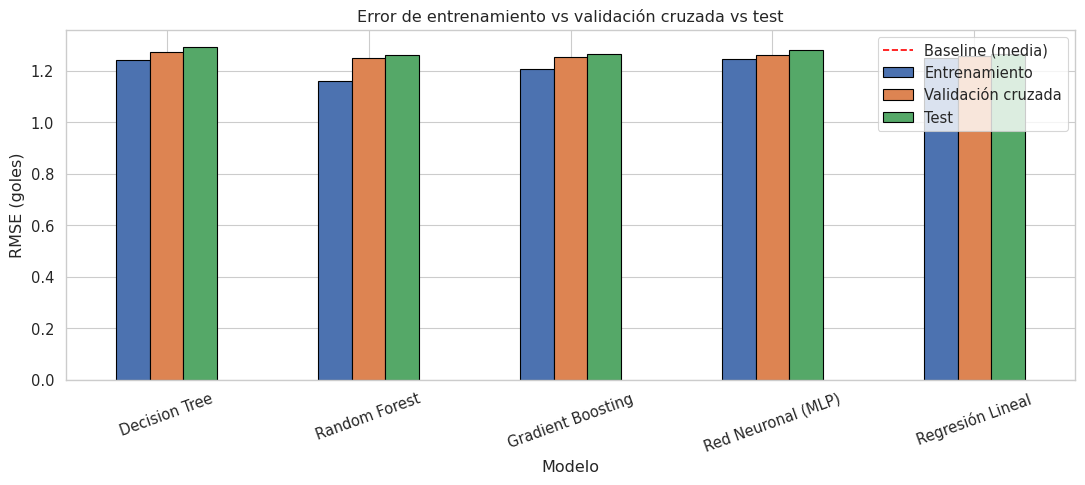

In [ ]:
filas = []
for nombre, modelo in mejores_modelos.items():
    rmse_tr = np.sqrt(mean_squared_error(y_dev_r, modelo.predict(X_dev_r)))
    filas.append({'Modelo': nombre,
                  'Entrenamiento': rmse_tr,
                  'Validación cruzada': rmse_cv[nombre],
                  'Test': resultados_reg[nombre]['RMSE']})
df_sobre = pd.DataFrame(filas).set_index('Modelo')
df_sobre['Brecha (CV - train)'] = df_sobre['Validación cruzada'] - df_sobre['Entrenamiento']
display(df_sobre.round(4))

ax = df_sobre[['Entrenamiento', 'Validación cruzada', 'Test']].plot(kind='bar', figsize=(11, 5), edgecolor='black')
ax.axhline(rmse_base, color='red', ls='--', label='Baseline (media)')
ax.set_ylabel('RMSE (goles)')
ax.set_title('Error de entrenamiento vs validación cruzada vs test')
ax.legend()
plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

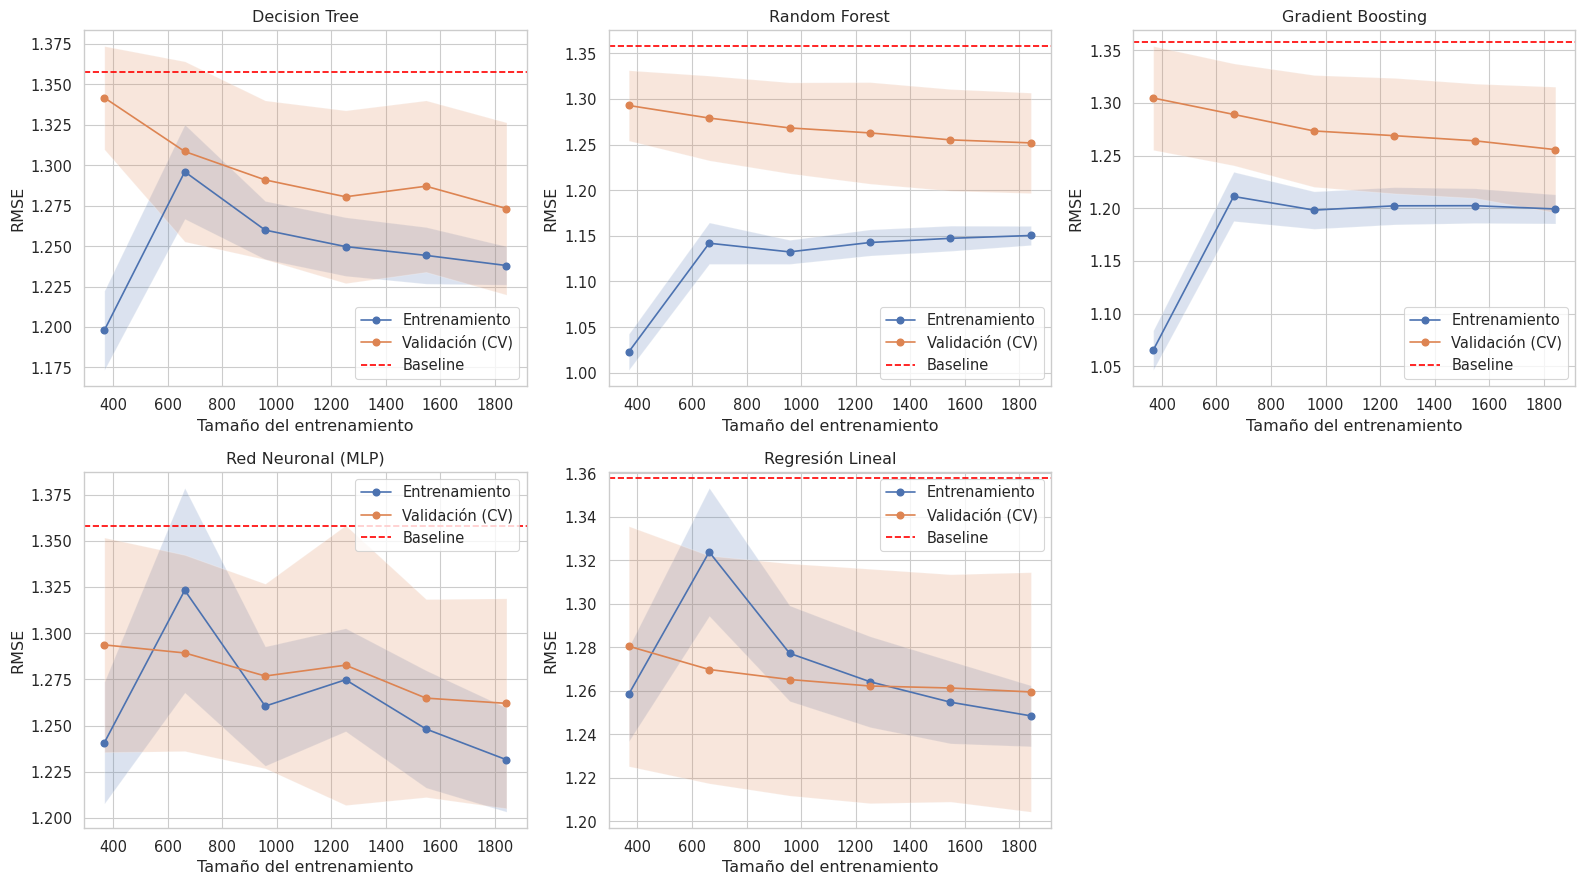

In [ ]:
from sklearn.model_selection import learning_curve

n = len(mejores_modelos)
filas_g = int(np.ceil(n / 3))
fig, axes = plt.subplots(filas_g, 3, figsize=(16, 4.5 * filas_g))
axes = axes.ravel()

for ax, (nombre, modelo) in zip(axes, mejores_modelos.items()):
    tam, tr, va = learning_curve(modelo, X_dev_r, y_dev_r, cv=cv,
                                 scoring='neg_root_mean_squared_error',
                                 train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1)
    tr, va = -tr, -va
    ax.plot(tam, tr.mean(axis=1), 'o-', label='Entrenamiento')
    ax.fill_between(tam, tr.mean(axis=1) - tr.std(axis=1), tr.mean(axis=1) + tr.std(axis=1), alpha=0.2)
    ax.plot(tam, va.mean(axis=1), 'o-', label='Validación (CV)')
    ax.fill_between(tam, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), alpha=0.2)
    ax.axhline(rmse_base, color='red', ls='--', label='Baseline')
    ax.set_title(nombre)
    ax.set_xlabel('Tamaño del entrenamiento'); ax.set_ylabel('RMSE')
    ax.legend()

for ax in axes[n:]:
    ax.axis('off')   # oculta los ejes sobrantes
plt.tight_layout(); plt.show()

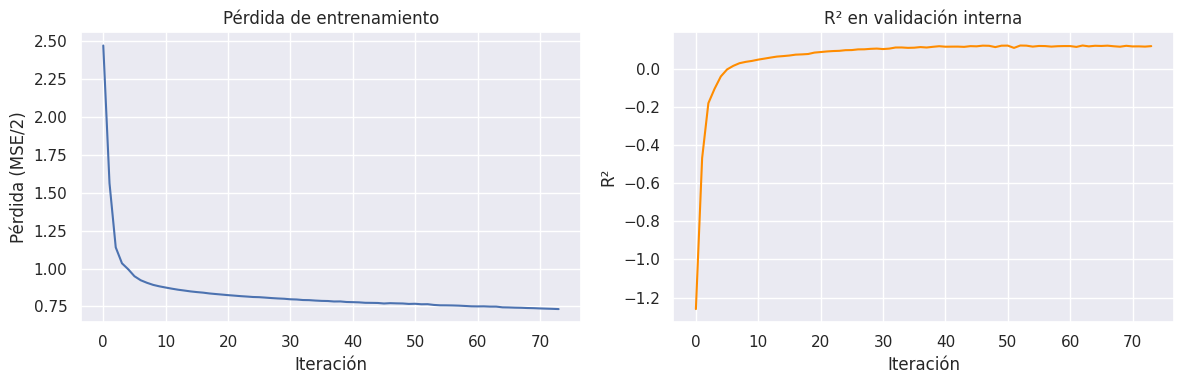

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(mlp.loss_curve_)
axes[0].set_title('Pérdida de entrenamiento')
axes[0].set_xlabel('Iteración'); axes[0].set_ylabel('Pérdida (MSE/2)')
axes[1].plot(mlp.validation_scores_, color='darkorange')
axes[1].set_title('R² en validación interna')
axes[1].set_xlabel('Iteración'); axes[1].set_ylabel('R²')
plt.tight_layout(); plt.show()

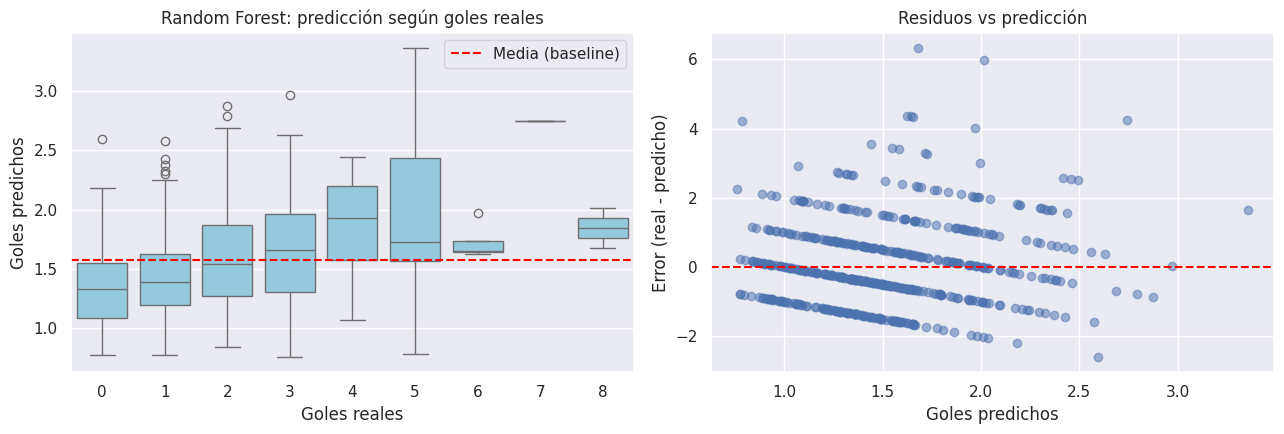

In [ ]:
mejor = top_3_modelos[0][0]
pred = resultados_reg[mejor]['Modelo'].predict(X_test_r)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Goles predichos según goles reales
df_pred = pd.DataFrame({'Goles reales': y_test_r.astype(int).values, 'Goles predichos': pred})
sns.boxplot(data=df_pred, x='Goles reales', y='Goles predichos', ax=axes[0], color='skyblue')
axes[0].axhline(y_train_r.mean(), color='red', ls='--', label='Media (baseline)')
axes[0].set_title(f'{mejor}: predicción según goles reales'); axes[0].legend()

# Residuos contra predicción
axes[1].scatter(pred, y_test_r.values - pred, alpha=0.5)
axes[1].axhline(0, color='red', ls='--')
axes[1].set_title('Residuos vs predicción')
axes[1].set_xlabel('Goles predichos'); axes[1].set_ylabel('Error (real - predicho)')

plt.tight_layout(); plt.show()

GRAFICAS

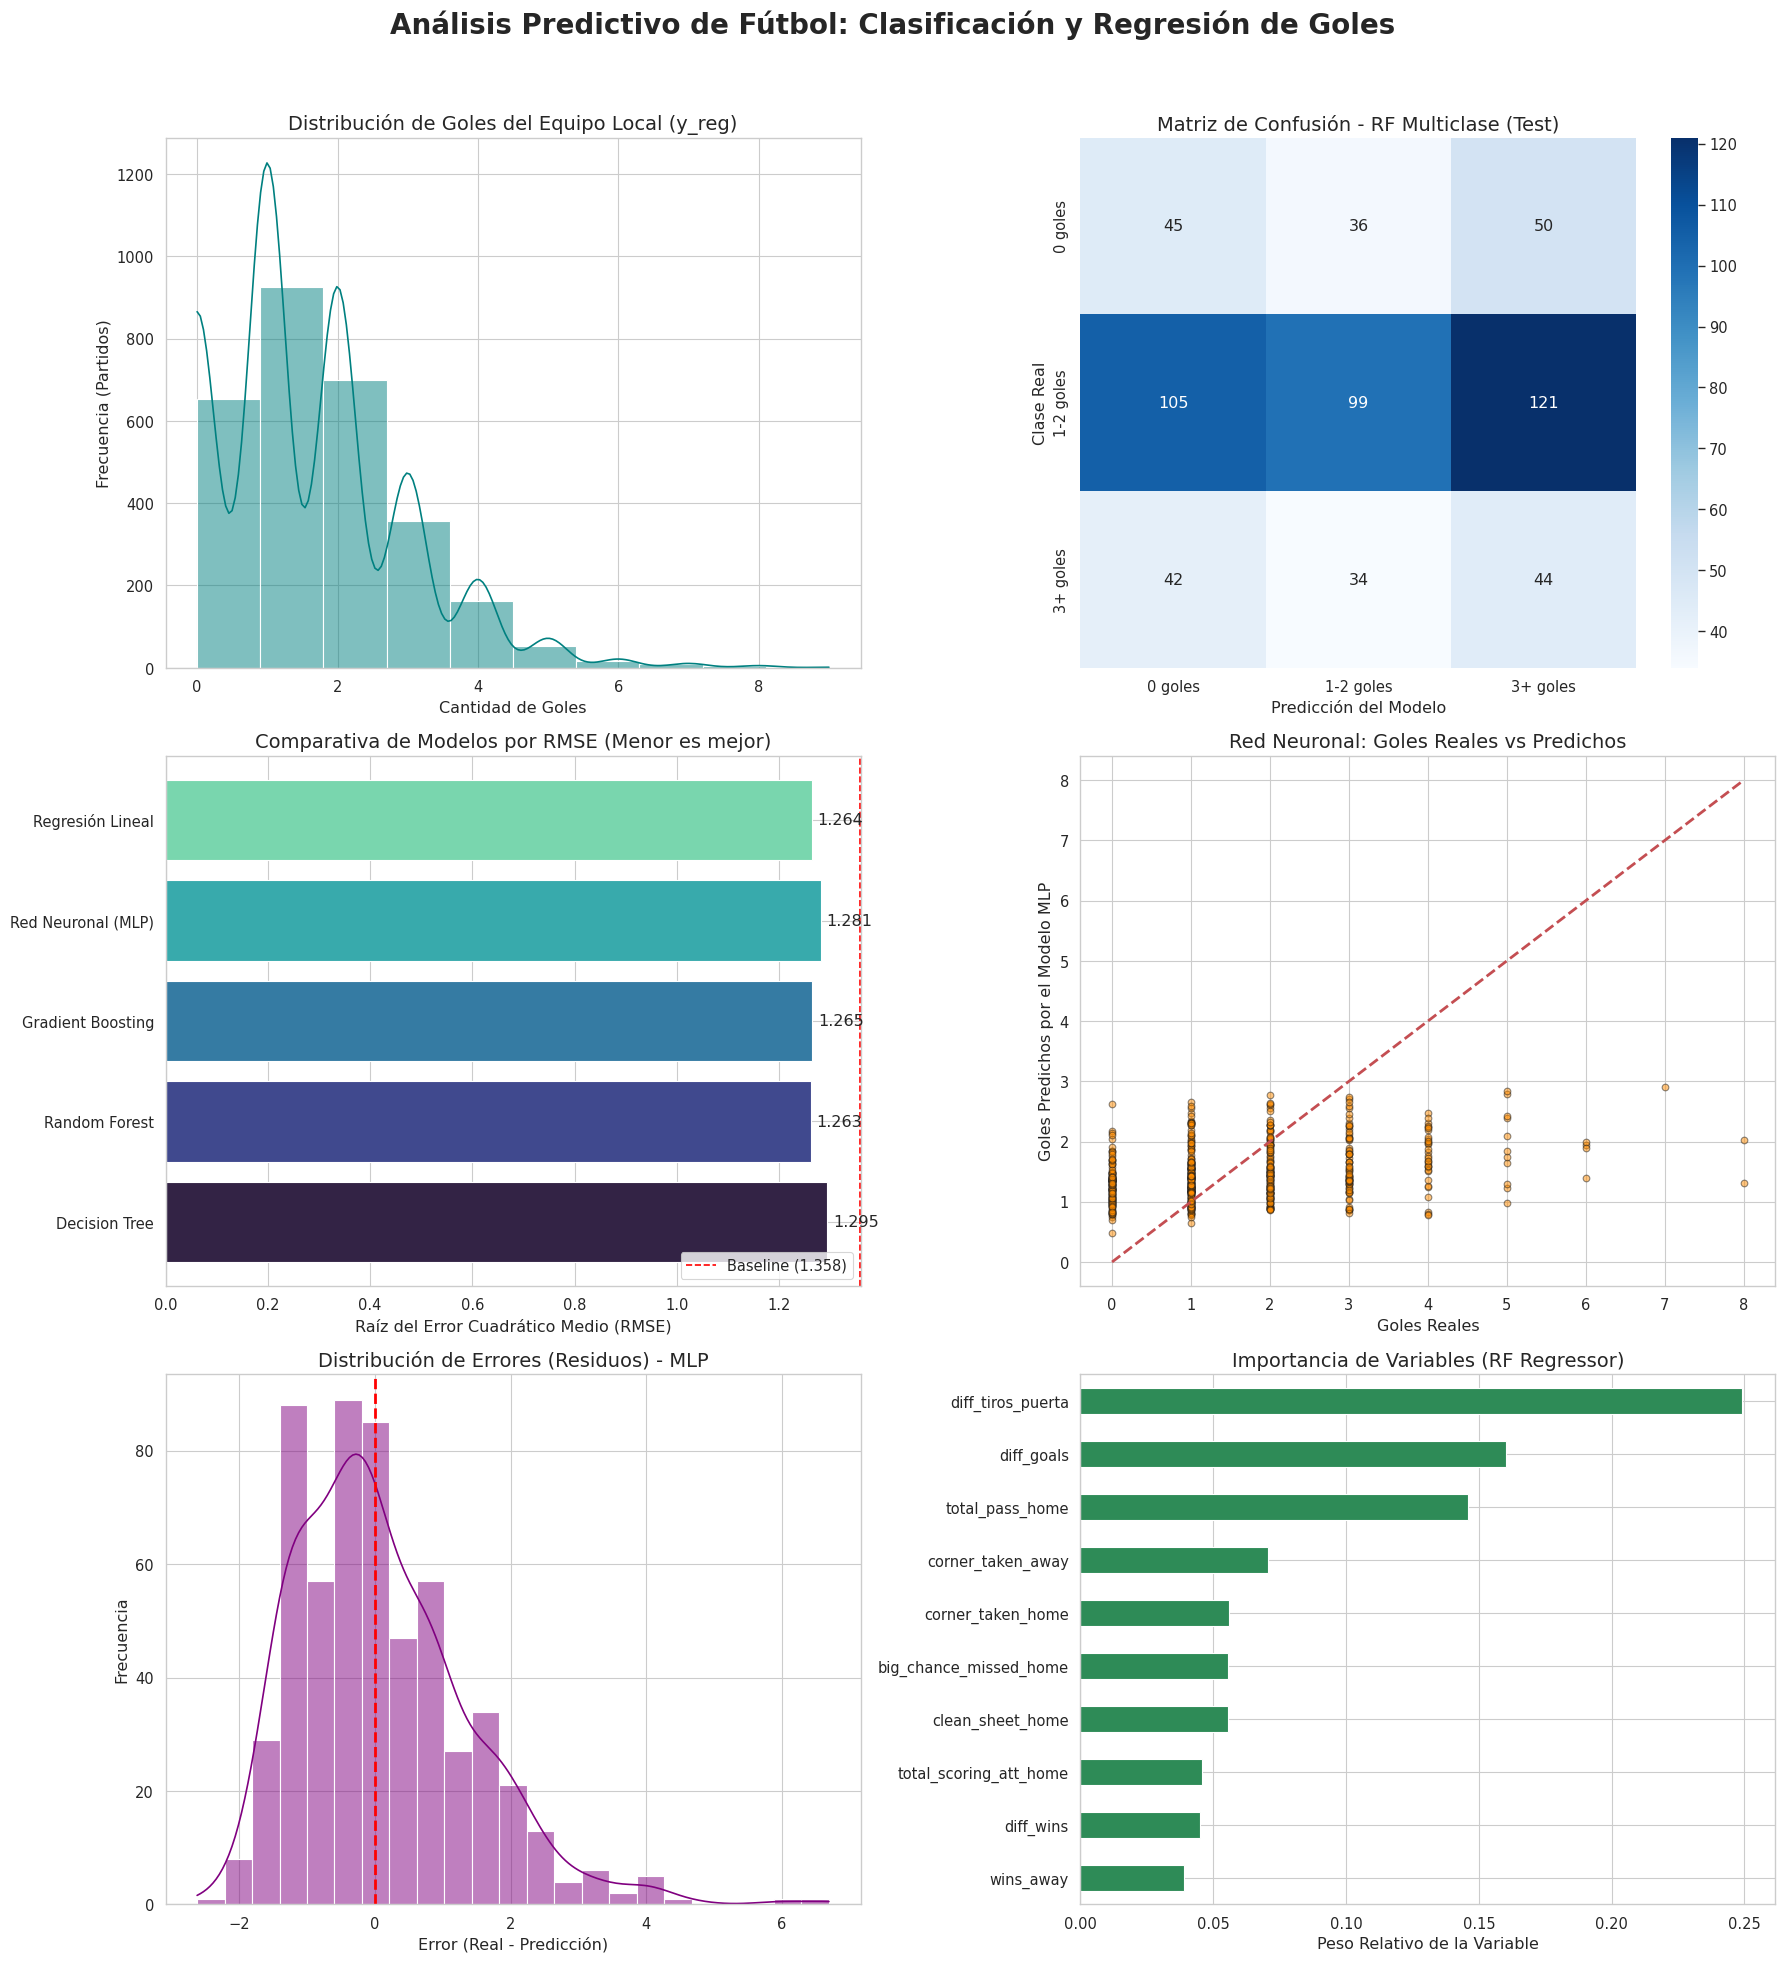

In [ ]:
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

fig, axes = plt.subplots(3, 2, figsize=(18, 20))
fig.suptitle('Análisis Predictivo de Fútbol: Clasificación y Regresión de Goles',
             fontsize=20, fontweight='bold', y=0.98)

# 1. Distribución de la variable objetivo
sns.histplot(y_reg, bins=10, kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Distribución de Goles del Equipo Local (y_reg)', fontsize=14)
axes[0, 0].set_xlabel('Cantidad de Goles')
axes[0, 0].set_ylabel('Frecuencia (Partidos)')

# 2. Matriz de confusión (clases 0 / 1-2 / 3+ goles)
etiquetas = ['0 goles', '1-2 goles', '3+ goles']
cm = confusion_matrix(y_test_m, y_pred_m, labels=[0, 1, 2])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 1],
            xticklabels=etiquetas, yticklabels=etiquetas)
axes[0, 1].set_title('Matriz de Confusión - RF Multiclase (Test)', fontsize=14)
axes[0, 1].set_xlabel('Predicción del Modelo')
axes[0, 1].set_ylabel('Clase Real')

# 3. Comparativa de RMSE
nombres_modelos = list(resultados_reg.keys()) + ['Red Neuronal (MLP)']
valores_rmse = [resultados_reg[n]['RMSE'] for n in resultados_reg] + [rmse_rn]
barras = axes[1, 0].barh(nombres_modelos, valores_rmse,
                         color=sns.color_palette("mako", len(nombres_modelos)))
axes[1, 0].bar_label(barras, fmt='%.3f', padding=4)
axes[1, 0].axvline(rmse_base, color='red', linestyle='--', label=f'Baseline ({rmse_base:.3f})')
axes[1, 0].legend(loc='lower right')
axes[1, 0].set_title('Comparativa de Modelos por RMSE (Menor es mejor)', fontsize=14)
axes[1, 0].set_xlabel('Raíz del Error Cuadrático Medio (RMSE)')

# 4. Real vs predicho (MLP)
axes[1, 1].scatter(y_test_r, predicciones_rn, alpha=0.5, color='darkorange', edgecolor='k')
axes[1, 1].plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], 'r--', lw=2)
axes[1, 1].set_title('Red Neuronal: Goles Reales vs Predichos', fontsize=14)
axes[1, 1].set_xlabel('Goles Reales')
axes[1, 1].set_ylabel('Goles Predichos por el Modelo MLP')

# 5. Residuos (MLP)
residuos = y_test_r - predicciones_rn
sns.histplot(residuos, kde=True, ax=axes[2, 0], color='purple')
axes[2, 0].axvline(x=0, color='red', linestyle='--', lw=2)
axes[2, 0].set_title('Distribución de Errores (Residuos) - MLP', fontsize=14)
axes[2, 0].set_xlabel('Error (Real - Predicción)')
axes[2, 0].set_ylabel('Frecuencia')

# 6. Importancia de variables (RF Regressor)
importancias_reg = pd.Series(resultados_reg['Random Forest']['Modelo'].feature_importances_,
                             index=X_train_r.columns)
importancias_reg.nlargest(10).sort_values().plot(kind='barh', color='seagreen', ax=axes[2, 1])
axes[2, 1].set_title('Importancia de Variables (RF Regressor)', fontsize=14)
axes[2, 1].set_xlabel('Peso Relativo de la Variable')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()